# Data curve: is the ~3.4 ceiling lack of data or the floor?
Decision 17: neither the learning rate (decision 16) nor the context window moved the validation minimum much below ~3.4. If the ceiling is lack of data, training on less data should be clearly worse and the curve should still be going down at 100%. If it flattens, more data won't help and the limit is elsewhere (capacity, or the floor of the problem).

Setup: same config as `run1_5ep` (lr 1e-5, batch 4, rank 8, 16 layers, seed 0), 5 epochs of each subset, checkpoints every 100. Only the train data changes:

- `adapters/data25`: `data/dataset/session_25`, 1,351 examples (25.0%), 146 of 463 train sessions, 1,689 steps.
- `adapters/data50`: `data/dataset/session_50`, 2,708 examples (50.1%), 269 sessions, 3,385 steps.
- 100%: `run1_5ep` at step 2500, already measured.

Subsets are nested by session (25 ⊂ 50 ⊂ 100, `build_subsets.py`), with the same `valid`. Following decision 17 (train with 6 turns, predict with 20), every model is evaluated with `nll_ejemplo` on `data/dataset/context/valid_ctx20.jsonl`, so the 100% point is 3.394 (Context.ipynb).

_My prediction:_ I don't think it's a data problem either. It will probably end up being capacity, either of the model or of the adapter, and given the overfitting we had, most likely the base model.

In [7]:
import json, math, os, random
import numpy as np
import mlx.core as mx
from mlx_lm import load
import matplotlib.pyplot as plt

MODELO = "mlx-community/Qwen2.5-0.5B-Instruct-4bit"

In [8]:
# Copied as is from Perplexity.ipynb
def nll_ejemplo(model, tokenizer, messages):
    full = tokenizer.apply_chat_template(messages)
    base_prompt = tokenizer.apply_chat_template(
        messages[:-1], add_generation_prompt=True)
    n_tokens = len(full) - len(base_prompt)
    logits = model(mx.array(full)[None])
    logits = logits[0, len(base_prompt)-1:len(full)-1]
    logits = logits.astype(mx.float32)
    logprobs = logits - mx.logsumexp(logits, axis=-1, keepdims=True)
    nll = 0
    for i in range(n_tokens):
        nll -= logprobs[i, full[len(base_prompt) + i]].item()
    mx.clear_cache()
    return (nll, n_tokens)

def medir(model, tokenizer, ruta):
    with open(ruta, "r") as f:
        ejemplos = [json.loads(line) for line in f if line.strip()]
    return [nll_ejemplo(model, tokenizer, e["messages"]) for e in ejemplos]

def resumen(resultados):
    nll = sum(r[0] for r in resultados)
    n = sum(r[1] for r in resultados)
    return nll / n

## Data and checkpoints

In [9]:
VALID_CTX20 = "../data/dataset/context/valid_ctx20.jsonl"
REF_100 = 3.394  # run1_5ep@2500 (100% of train), 20 turns at prediction (Context.ipynb)

RUNS = {
    # percent of train examples: (adapter, examples, checkpoints to measure)
    25: ("../adapters/data25", 1351, list(range(100, 1401, 100))),  # stopped at 1400 on purpose, see below
    50: ("../adapters/data50", 2708, list(range(200, 3301, 200))),
}

with open(VALID_CTX20) as f:
    n_valid = sum(1 for l in f if l.strip())
with open("../data/dataset/context/valid_meta.json") as f:
    sesion = [e["session"] for e in json.load(f)["examples"]]  # for the bootstrap by session
assert n_valid == len(sesion) == 1012, (n_valid, len(sesion))

for p, (adaptador, _, pasos) in RUNS.items():
    faltan = [s for s in pasos if not os.path.exists(f"{adaptador}/{s:07d}_adapters.safetensors")]
    print(f"data{p}: {len(pasos) - len(faltan)}/{len(pasos)} checkpoints present" + (f", missing {faltan}" if faltan else ""))

data25: 14/14 checkpoints present
data50: 16/16 checkpoints present


## Measure
Same as ContextRetrain.ipynb: keeps `(nll, tokens)` per example, saves after every checkpoint and skips the ones already in the file, so I can stop and resume. Each run can be measured as soon as its training finishes.

In [10]:
def curva_por_ejemplo(adaptador, ruta_valid, pasos, salida):
    # Resume from a previous partial run if the file exists.
    if os.path.exists(salida):
        with open(salida) as f:
            resultados = json.load(f)
    else:
        resultados = {
            "source": "experiments/DataCurve.ipynb",
            "model": MODELO,
            "adapter": adaptador.removeprefix("../"),
            "data": ruta_valid.removeprefix("../"),
            "learning_rate": 1e-5,
            "session": sesion,
            "valid": {},
            # Per example, in valid_ctx20.jsonl order: [nll_sum, n_tokens].
            "per_example": {},
        }
    model = None  # loaded only if some checkpoint is still missing, so a fully cached run is instant
    for paso in pasos:
        if str(paso) in resultados["per_example"]:
            print(f"step {paso:>4}: loss {resultados['valid'][str(paso)]:.3f} (cached)")
            continue
        if model is None:
            model, tokenizer = load(MODELO, adapter_path=adaptador)
        model.load_weights(f"{adaptador}/{paso:07d}_adapters.safetensors", strict=False)
        r = medir(model, tokenizer, ruta_valid)
        resultados["per_example"][str(paso)] = r
        resultados["valid"][str(paso)] = resumen(r)
        with open(salida, "w") as f:
            json.dump(resultados, f)
        print(f"step {paso:>4}: loss {resumen(r):.3f}")
    return resultados

In [11]:
adaptador, _, pasos = RUNS[25]
data25 = curva_por_ejemplo(adaptador, VALID_CTX20, pasos, "results/checkpoints_data25.json")

step  100: loss 3.638 (cached)
step  200: loss 3.588 (cached)
step  300: loss 3.539 (cached)
step  400: loss 3.560 (cached)
step  500: loss 3.559 (cached)
step  600: loss 3.555 (cached)
step  700: loss 3.604 (cached)
step  800: loss 3.656 (cached)
step  900: loss 3.646 (cached)
step 1000: loss 3.666 (cached)
step 1100: loss 3.837 (cached)
step 1200: loss 3.810 (cached)
step 1300: loss 3.840 (cached)
step 1400: loss 4.102 (cached)


I manually stopped the train as it was not improving validation scores. Did not make sense to keep extracting data.

In [12]:
adaptador, _, pasos = RUNS[50]
data50 = curva_por_ejemplo(adaptador, VALID_CTX20, pasos, "results/checkpoints_data50.json")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  200: loss 3.615
step  400: loss 3.526
step  600: loss 3.489
step  800: loss 3.491
step 1000: loss 3.497
step 1200: loss 3.474
step 1400: loss 3.522
step 1600: loss 3.545
step 1800: loss 3.537
step 2000: loss 3.528
step 2200: loss 3.648
step 2400: loss 3.659


KeyboardInterrupt: 

## Results
Best checkpoint of each run (picked on this same `valid`, as for 100%), and a 95% CI of its loss resampling sessions (1000, with replacement, seed 0), as in Perplexity.ipynb. The 100% per-example values come from `results/context_v1.json`.

In [13]:
# Copied from Context.ipynb
def por_sesion(resultados, etiquetas):
    sumas = {}
    for (nll, n), s in zip(resultados, etiquetas):
        if s not in sumas:
            sumas[s] = [0.0, 0]
        sumas[s][0] += nll
        sumas[s][1] += n
    return sumas

def perdida(sumas, elegidas):
    nll, n = 0.0, 0
    for s in elegidas:
        nll += sumas.get(s, [0.0, 0])[0]
        n += sumas.get(s, [0.0, 0])[1]
    return nll / n

def intervalo(resultados, etiquetas, repeticiones=1000):
    # 95% CI of the token-weighted loss, resampling sessions.
    sumas = por_sesion(resultados, etiquetas)
    sesiones = sorted(sumas)
    random.seed(0)
    medias = [perdida(sumas, random.choices(sesiones, k=len(sesiones))) for _ in range(repeticiones)]
    return np.percentile(medias, [2.5, 97.5])

def diferencia(r_antes, r_despues, etiquetas, repeticiones=1000):
    # Paired: (despues - antes) on the same replies, 95% CI resampling sessions.
    s_antes, s_despues = por_sesion(r_antes, etiquetas), por_sesion(r_despues, etiquetas)
    sesiones = sorted(s_antes)
    random.seed(0)
    difs = []
    for _ in range(repeticiones):
        elegidas = random.choices(sesiones, k=len(sesiones))
        difs.append(perdida(s_despues, elegidas) - perdida(s_antes, elegidas))
    return resumen(r_despues) - resumen(r_antes), *np.percentile(difs, [2.5, 97.5])

In [14]:
with open("results/context_v1.json") as f:
    r100 = json.load(f)["per_example"]["adapter"]["20"]  # run1_5ep@2500, 20 turns
assert abs(resumen(r100) - REF_100) < 0.005, resumen(r100)

def mejor(datos):
    valid = {int(k): v for k, v in datos["valid"].items()}
    paso = min(valid, key=valid.get)
    return paso, datos["per_example"][str(paso)]

# Read from the JSON files, not the variables above: works after a restart or an interrupted measurement.
datos_runs = {}
for p in RUNS:
    ruta = f"results/checkpoints_data{p}.json"
    if os.path.exists(ruta):
        with open(ruta) as f:
            datos_runs[p] = json.load(f)
    else:
        print(f"data{p}: not measured yet, left out")

puntos = {}  # percent -> (step, per-example results)
for p, datos in datos_runs.items():
    puntos[p] = mejor(datos)
puntos[100] = (2500, r100)

print(f"{'data':>5} {'examples':>8} {'best step':>9} {'epoch':>6} {'valid nll':>9} {'95% CI':>16} {'vs 100%':>8} {'95% CI (paired)':>18}")
ejemplos = {p: RUNS[p][1] for p in RUNS} | {100: 5404}
for p, (paso, r) in puntos.items():
    lo, hi = intervalo(r, sesion)
    linea = f"{p:>4}% {ejemplos[p]:>8} {paso:>9} {paso * 4 / ejemplos[p]:>6.2f} {resumen(r):>9.3f} [{lo:.3f}, {hi:.3f}]"
    if p != 100:
        d, dlo, dhi = diferencia(r100, r, sesion)
        linea += f" {d:>+8.3f} [{dlo:+.3f}, {dhi:+.3f}]"
    print(linea)

 data examples best step  epoch valid nll           95% CI  vs 100%    95% CI (paired)
  25%     1351       300   0.89     3.539 [3.411, 3.612]   +0.145 [+0.125, +0.182]
  50%     2708      1200   1.77     3.474 [3.332, 3.544]   +0.080 [+0.067, +0.097]
 100%     5404      2500   1.85     3.394 [3.250, 3.455]


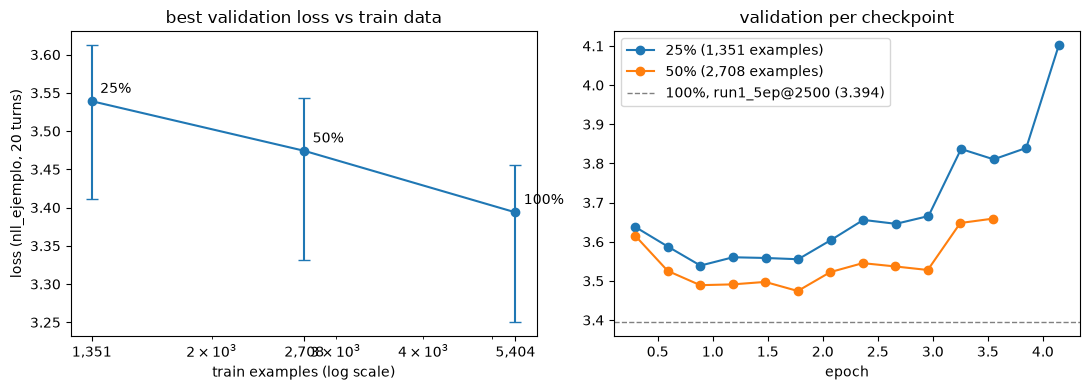

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

# Left: best valid loss vs amount of train data, with the CI by session.
xs = sorted(puntos)
ys = [resumen(puntos[p][1]) for p in xs]
cis = [intervalo(puntos[p][1], sesion) for p in xs]
ejes[0].errorbar([ejemplos[p] for p in xs], ys,
                 yerr=[[y - lo for y, (lo, _) in zip(ys, cis)], [hi - y for y, (_, hi) in zip(ys, cis)]],
                 marker="o", capsize=4)
for p, x, y in zip(xs, [ejemplos[p] for p in xs], ys):
    ejes[0].annotate(f"{p}%", (x, y), textcoords="offset points", xytext=(6, 6))
ejes[0].set_xscale("log")
ejes[0].set_xticks([ejemplos[p] for p in xs], [f"{ejemplos[p]:,}" for p in xs])
ejes[0].set_title("best validation loss vs train data")
ejes[0].set_xlabel("train examples (log scale)"); ejes[0].set_ylabel("loss (nll_ejemplo, 20 turns)")

# Right: per-step curves. 100% only has its chosen checkpoint at 20 turns, so it's a line.
for p, datos in datos_runs.items():
    valid = {int(k): v for k, v in sorted(datos["valid"].items(), key=lambda kv: int(kv[0]))}
    ejes[1].plot([s * 4 / ejemplos[p] for s in valid], list(valid.values()), marker="o", label=f"{p}% ({ejemplos[p]:,} examples)")
ejes[1].axhline(REF_100, color="gray", linestyle="--", linewidth=1, label=f"100%, run1_5ep@2500 ({REF_100})")
ejes[1].set_title("validation per checkpoint"); ejes[1].set_xlabel("epoch"); ejes[1].legend()
plt.tight_layout()
plt.show()

### Conclusion

| data | examples | best step | epochs | valid nll (20 turns) | vs 100% (paired, 95% CI) |
|---|---|---|---|---|---|
| 25% | 1,351 | 300 | 0.89 | 3.539 | +0.145 [+0.125, +0.182] |
| 50% | 2,708 | 1200 | 1.77 | 3.474 | +0.080 [+0.067, +0.097] |
| 100% | 5,404 | 2500 | 1.85 | 3.394 | |

My prediction was wrong: it is a data problem. Each time the data doubles, validation drops ~0.07-0.08, and the curve doesn't flatten (the last step, 50 to 100%, is even a bit larger). The paired bootstrap by session leaves no doubt: both smaller subsets are clearly worse than 100%. I stopped the data50 measurement at step 2400 on purpose, as with data25: validation had been going up since step 1200.

Caveat: the 100% checkpoint was picked on the 6-turn `valid`, the other two on this 20-turn one.

There isn't much more data. The newer WhatsApp copy adds about 20% more, which by this curve would be ~0.26 of a doubling, so roughly −0.02: close to the noise and very hard to measure. I won't retrain with it.

Next: stop looking only at the loss and measure whether the generated replies sound like me, with a text classifier (BERT-style) trained on my messages vs my friends'.